In [1]:
from ISMgas.fitting.systemic_redshift import Fitter
from ISMgas.SupportingFunctions import load_QFitsview_spectra, overlayAllLines
import matplotlib.pyplot as plt 

(3500.0, 5824.0)

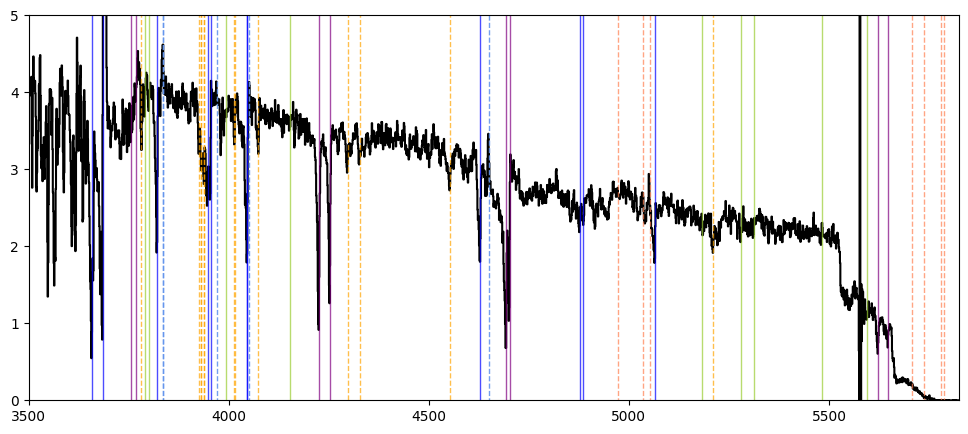

In [2]:
plt.figure(figsize=(12,5))
wave,flux = load_QFitsview_spectra("example_spec")

zs = 2.032 ## Guess redshift
overlayAllLines(zfactor = (1+zs))

flux *= 1e-2
## Make a mock error spectra
error_mock = flux*0.1
plt.ylim([0,5])
plt.xlim([3500, wave[-1]])

Running 1Running 2Running 0Running 5Running 3Running 4Running 8
Running 7Running 6Running 10Running 9Running 12
Running 13


Running 11

Running 14







Running 15
Running 16
Running 17
Running 18
Running 19


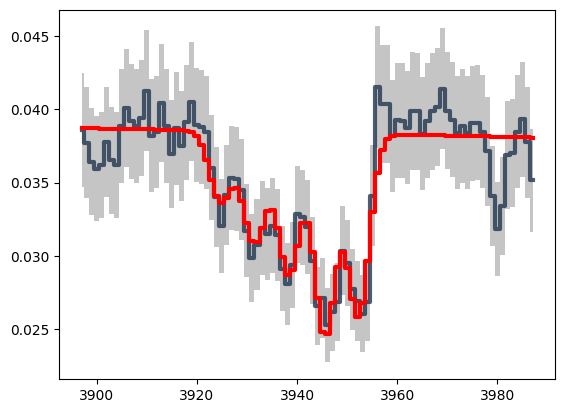

In [3]:
zFit = Fitter(
    wave = wave,
    flux= flux,
    err = error_mock,
    zs = zs,
    objid = 'test'
)
priors = {
        'p0':{'value':-0.00001, 'min':-0.04, 'max':0},
        'p1':{'value':-0.00001, 'min':-0.04, 'max':0},
        'p2':{'value':-0.00001, 'min':-0.04, 'max':0},
        'p3':{'value':-0.00001, 'min':-0.04,   'max':0},
        'p4':{'value':-0.00001, 'min':-0.04,   'max':0},
        'p5':{'value':-0.001,  'min':-0.05,   'max':0},
        'p6':{'value':0.001,   'min':0, 'max':0.000001},
        'z1':{'value':zs, 'min':zs - 0.001, 'max':zs + 0.001},
        'z2':{'value':zs - 0.002, 'min':zs - 0.005, 'max':zs + 0.005},
        'z3':{'value':zs, 'min':zs - 0.001, 'max':zs + 0.001},   
        'sigma1':{'value':0.0001,   'min':0.0, 'max':0.0005},
        'sigma2':{'value':0.0001,   'min':0.0, 'max':0.0005},
        'sigma3':{'value':0.0001,   'min':0.0, 'max':0.0005},
        'p9':{'value':0.05,   'min':-0.05, 'max':1},
        'p10':{'value':-0.001,  'min':-1, 'max':1 }
    }

results = zFit.stellar1300(niter=20, plotting=True, priors=priors)

In [4]:
results

{'best_fit': {'zstars': [2.031880216238682, 0.00013704505558359765],
  'zism': [2.0299416584886387, 0.0002657231220001729],
  'zfineem': [2.0321731758945445, 0.0010496148314689093],
  'sigma_stellar': [0.00021966454447573433, 2.1953231802303556e-05],
  'sigma_ism': [0.00021770340000010788, 1.8775351935529502e-05],
  'sigma_fineem': [0.000255750531610579, 0.00017483757201711966],
  'p0': [-0.004832715993066509, 0.001354534336648097],
  'p1': [-1.6270104006219088e-06, 2.408739542336874e-06],
  'p2': [-0.007524473391548971, 0.0016985917666518873],
  'p3': [-0.009691208425427852, 0.0014236512574923768],
  'p4': [-0.013787749122709251, 0.001823178860865187],
  'p5': [-0.012366080079876732, 0.0012775968840041528],
  'p6': [8.918518584791298e-07, 1.5820925232203306e-07],
  'p9': [0.06520722269845976, 0.007939763090202863],
  'p10': [0.221171280977847, 0.052325928680346835],
  'wave': <Column name='Wave' dtype='float64' length=91>
  3897.0
  3898.0
  3899.0
  3900.0
  3901.0
  3902.0
  3903.0


(3700.0, 4100.0)

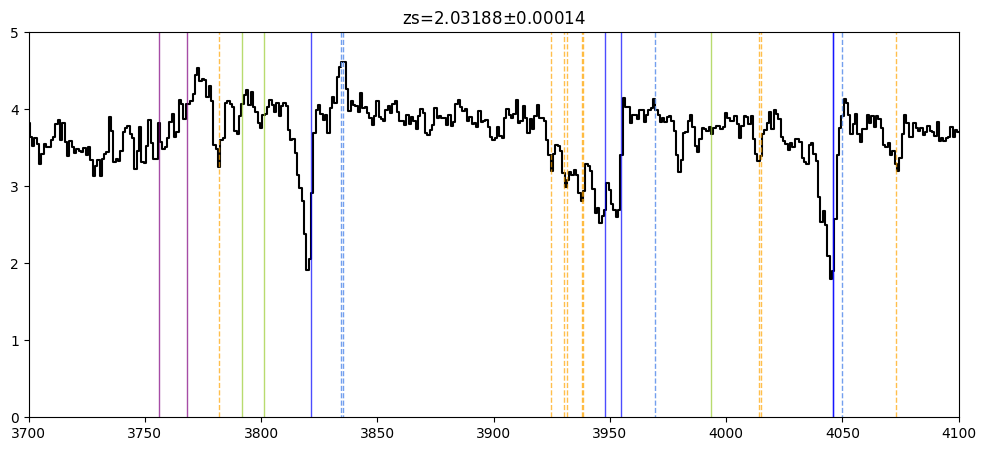

In [5]:
plt.figure(figsize=(12,5))
wave,flux = load_QFitsview_spectra("example_spec")

zs = results['best_fit']['zstars'][0] ## best fit redshift
zsErr = results['best_fit']['zstars'][1] ## error

overlayAllLines(zfactor = (1+zs))
plt.title(f"zs={zs:.5f}$\pm${zsErr:.5f}")
plt.ylim([0,5])
plt.xlim([3700, 4100])